# ML Zoomcamp 2026 - Homework 4

Evaluation metrics for classification.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split, KFold

## Data preparation

In [7]:
url = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv'
df = pd.read_csv(url)
df.head()

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [8]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

df[categorical] = df[categorical].fillna('NA')
df[numerical] = df[numerical].fillna(0.0)

df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

len(df_train), len(df_val), len(df_test)

(3000, 1000, 1000)

## Q1 - ROC AUC feature importance

In [9]:
y_train = df_train.converted

for col in numerical:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    print(col, round(auc, 3))

annual_income 0.608
number_of_courses_viewed 0.723
interaction_count 0.765
lead_score 0.788


## Q2 - Model AUC

In [10]:
def train_model(train, val, C=1.0):
    dv = DictVectorizer()
    X_train = dv.fit_transform(train.drop(columns='converted').to_dict(orient='records'))
    X_val = dv.transform(val.drop(columns='converted').to_dict(orient='records'))

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, train.converted)
    return model.predict_proba(X_val)[:, 1]


y_val = df_val.converted.values
y_pred = train_model(df_train, df_val)
print('Validation AUC:', round(roc_auc_score(y_val, y_pred), 3))

Validation AUC: 0.732


## Q3 and Q4 - Precision, recall and F1

In [15]:
thresholds = np.arange(0, 1.01, 0.01)
results = []

for t in thresholds:
    pred = y_pred >= t
    tp = ((pred == 1) & (y_val == 1)).sum()
    fp = ((pred == 1) & (y_val == 0)).sum()
    fn = ((pred == 0) & (y_val == 1)).sum()

    p = tp / (tp + fp) if tp + fp > 0 else 0
    r = tp / (tp + fn) if tp + fn > 0 else 0
    f1 = 2 * p * r / (p + r) if p + r > 0 else 0
    results.append((t, p, r, f1))

scores = pd.DataFrame(results, columns=['threshold', 'precision', 'recall', 'f1'])

not_zero = scores[(scores.precision != 0) | (scores.recall != 0)]
closest = (not_zero.precision - not_zero.recall).abs().idxmin()
best_f1 = scores.f1.idxmax()

print('Q3 - Precision and Recall:', round(scores.loc[closest, 'threshold'], 2))
print('Q4 - F1:', round(scores.loc[best_f1, 'threshold'], 2))

Q3 - Precision and Recall: 0.63
Q4 - F1: 0.41


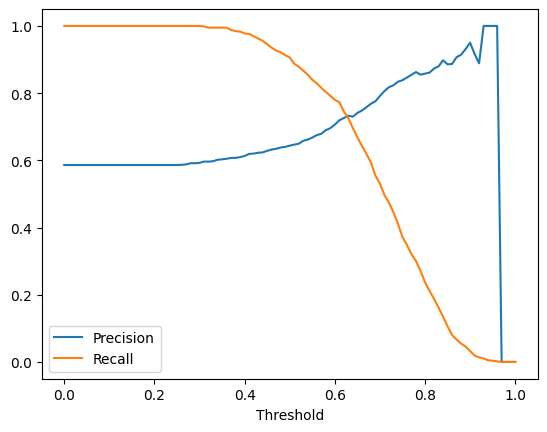

In [12]:
plt.plot(scores.threshold, scores.precision, label='Precision')
plt.plot(scores.threshold, scores.recall, label='Recall')
plt.xlabel('Threshold')
plt.legend()
plt.show()

## Q5 - 5-fold cross-validation

In [13]:
def cross_validation(data, C=1.0):
    kfold = KFold(n_splits=5, shuffle=True, random_state=1)
    aucs = []

    for train_idx, val_idx in kfold.split(data):
        train = data.iloc[train_idx]
        val = data.iloc[val_idx]
        pred = train_model(train, val, C)
        aucs.append(roc_auc_score(val.converted, pred))

    return np.array(aucs)


aucs = cross_validation(df_full_train)
print('Fold AUCs:', np.round(aucs, 3))
print('Q5:', round(aucs.std(), 3))

Fold AUCs: [0.731 0.73  0.736 0.741 0.721]
Q5: 0.007


## Q6 - Best C

In [14]:
results = []
for C in [0.000001, 0.001, 1]:
    aucs = cross_validation(df_full_train, C)
    results.append((C, round(aucs.mean(), 3), round(aucs.std(), 3)))

cv_results = pd.DataFrame(results, columns=['C', 'mean_auc', 'std_auc'])
display(cv_results)

best = cv_results.sort_values(['mean_auc', 'std_auc', 'C'], ascending=[False, True, True]).iloc[0]
print('Q6:', best.C)

,C,mean_auc,std_auc
0,0.000001,0.617,0.019
1,0.001000,0.749,0.010
2,1.000000,0.732,0.007


Q6: 0.001
